<a href="https://colab.research.google.com/github/tkach3nkoo/MN/blob/main/%D0%9B%D0%A0_8_%D0%A2%D0%BA%D0%B0%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B3%D1%80%D1%83%D0%BF%D0%B0_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Виконав:** Ткаченко  
**Мета:** навчитися кластеризувати дані алгоритмом K-Means, оцінювати кількість кластерів методом ліктя і коефіцієнтом силуета, виконувати PCA. Додатково — порівняти три класифікатори на даних студентів.

**Середовище:** Google Colab / Jupyter Notebook, Python 3, `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`. Необов'язкові: `kneed`, `yellowbrick`, `kagglehub`.

**Дані завдання 2:** [Students Performance Dataset (Rabie El Kharoua)](https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset), файл `Student_performance_data _.csv`. Спочатку перевіряється локальний CSV, потім здійснюється спроба автоматичного завантаження. Якщо інтернет недоступний, помістіть CSV поряд із ноутбуком і перезапустіть усі комірки. Синтетичні дані замість оригінального набору **не** використовуються.

**Виконання:** запускати всі комірки послідовно від початку до кінця. `random_state=42` для відтворюваності. Результати порівнянь і підсумкові числа друкуються програмою, а не задаються вручну.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
print("Бібліотеки для завдання 1 імпортовано.")

Бібліотеки для завдання 1 імпортовано.


**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris(as_frame=True)
iris_df = iris.data.copy()
print(f"Iris: {iris_df.shape[0]} зразків, {iris_df.shape[1]} ознаки.")
display(iris_df.head())

Iris: 150 зразків, 4 ознаки.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

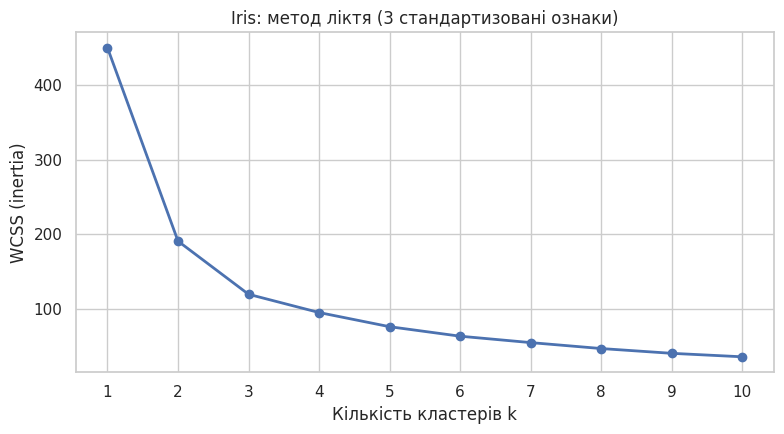

Використані ознаки: sepal length (cm), sepal width (cm), petal length (cm)
WCSS: {1: np.float64(450.0), 2: np.float64(190.47), 3: np.float64(119.14), 4: np.float64(94.64), 5: np.float64(75.63), 6: np.float64(62.87), 7: np.float64(54.28), 8: np.float64(46.31), 9: np.float64(39.89), 10: np.float64(35.23)}


In [3]:
# Обираємо перші три з чотирьох ознак Iris й надалі всюди використовуємо саме їх.
iris_features = list(iris_df.columns[:3])
iris_X = iris_df[iris_features]
iris_scaler = StandardScaler()
iris_scaled = iris_scaler.fit_transform(iris_X)

iris_k_values = list(range(1, 11))
iris_wcss = [KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
             .fit(iris_scaled).inertia_ for k in iris_k_values]

plt.figure(figsize=(8, 4.5))
plt.plot(iris_k_values, iris_wcss, "o-", linewidth=2)
plt.xticks(iris_k_values)
plt.xlabel("Кількість кластерів k")
plt.ylabel("WCSS (inertia)")
plt.title("Iris: метод ліктя (3 стандартизовані ознаки)")
plt.tight_layout()
plt.show()
print("Використані ознаки:", ", ".join(iris_features))
print("WCSS:", dict(zip(iris_k_values, np.round(iris_wcss, 2))))

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

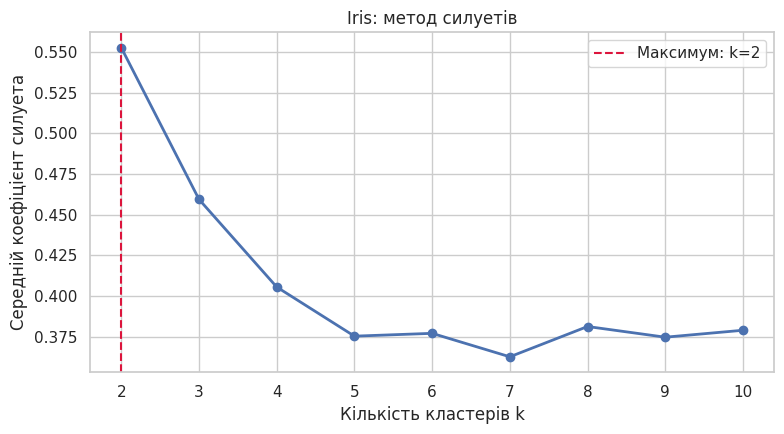

Найкраща кількість за силуетом: 2, silhouette=0.5525


In [4]:
iris_silhouette = {}
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(iris_scaled)
    iris_silhouette[k] = silhouette_score(iris_scaled, labels)

iris_best_sil_k = max(iris_silhouette, key=iris_silhouette.get)
plt.figure(figsize=(8, 4.5))
plt.plot(list(iris_silhouette), list(iris_silhouette.values()), "o-", linewidth=2)
plt.axvline(iris_best_sil_k, color="crimson", linestyle="--", label=f"Максимум: k={iris_best_sil_k}")
plt.xticks(range(2, 11))
plt.xlabel("Кількість кластерів k")
plt.ylabel("Середній коефіцієнт силуета")
plt.title("Iris: метод силуетів")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Найкраща кількість за силуетом: {iris_best_sil_k}, "
      f"silhouette={iris_silhouette[iris_best_sil_k]:.4f}")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

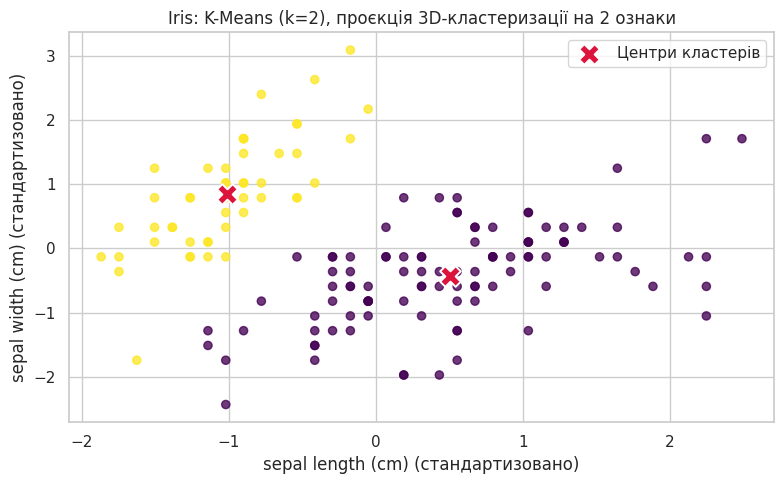

Розміри кластерів: {np.int32(0): np.int64(100), np.int32(1): np.int64(50)}
Силует для фінальної моделі k=2: 0.5525


In [5]:
iris_final_model = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
iris_labels = iris_final_model.fit_predict(iris_scaled)
centers = iris_final_model.cluster_centers_

plt.figure(figsize=(8, 5))
scatter = plt.scatter(iris_scaled[:, 0], iris_scaled[:, 1], c=iris_labels,
                      cmap="viridis", s=35, alpha=0.78)
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=220,
            color="crimson", edgecolor="white", linewidth=1.4,
            label="Центри кластерів")
plt.xlabel(f"{iris_features[0]} (стандартизовано)")
plt.ylabel(f"{iris_features[1]} (стандартизовано)")
plt.title("Iris: K-Means (k=2), проєкція 3D-кластеризації на 2 ознаки")
plt.legend()
plt.tight_layout()
plt.show()

print("Розміри кластерів:", dict(zip(*np.unique(iris_labels, return_counts=True))))
print(f"Силует для фінальної моделі k=2: {iris_silhouette[2]:.4f}")

### Висновок до завдання 1
Метод ліктя демонструє помітне зменшення WCSS за збільшення `k` на початку графіка; точка зміни темпу зменшення може інтерпретуватися як **2–3 кластери**. Метод силуетів для трьох вибраних ознак має максимум при **`k=2`** (точне значення обчислюється вище). Тому фінальну модель за умовою роботи побудовано для **двох кластерів**. Класи Iris мають три ботанічні категорії, але кластеризація не зобов'язана відтворювати ці мітки, особливо після вибору лише трьох ознак. На графіку показано тільки перші дві координати, хоча модель навчалася на трьох.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.decomposition import PCA

# Універсальний код для Colab, Jupyter та локального запуску.
# Імпорт google.colab виконується тільки тоді, коли справді потрібний.
print("Інструменти для класифікації імпортовано.")

Інструменти для класифікації імпортовано.


**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
# Шукаємо оригінальний CSV; ніякі альтернативні або синтетичні набори не підміняються.
local_names = ["Student_performance_data _.csv", "Student_performance_data_.csv", "Student_data.csv"]
folders = [Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
dataset_path = next((folder / name for folder in folders for name in local_names
                     if (folder / name).is_file()), None)

if dataset_path is None:
    # Дзеркало оригінального публічного Kaggle CSV; потрібен доступ до інтернету.
    source_url = ("https://raw.githubusercontent.com/Arihant-Golchha/"
                  "Student-Performance-Predictor/main/Student_performance_data%20_.csv")
    try:
        from urllib.request import urlretrieve
        dataset_path = Path.cwd() / "Student_performance_data _.csv"
        urlretrieve(source_url, dataset_path)
        print("Завантажено відкритий CSV з GitHub-дзеркала набору Kaggle.")
    except Exception as error:
        dataset_path = None
        print("Автоматичне завантаження недоступне:", type(error).__name__)
        print("Для обчислень завдання 2 завантажте оригінальний CSV з Kaggle,")
        print("покладіть 'Student_performance_data _.csv' поруч із ноутбуком і запустіть усі комірки.")

if dataset_path is not None:
    print("Шлях до CSV:", dataset_path)

Завантажено відкритий CSV з GitHub-дзеркала набору Kaggle.
Шлях до CSV: /content/Student_performance_data _.csv


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
df = None
if dataset_path is not None:
    candidate = pd.read_csv(dataset_path)
    required_columns = {"StudentID", "GradeClass", "Age", "StudyTimeWeekly", "Absences", "GPA"}
    missing_columns = required_columns.difference(candidate.columns)
    if missing_columns:
        print("ПОМИЛКА: у файлі відсутні необхідні поля:", sorted(missing_columns))
    else:
        df = candidate
        print(f"Набір студентів: {df.shape[0]} рядків, {df.shape[1]} стовпців")
        display(df.head())

DATA_READY = df is not None
if not DATA_READY:
    print("Завдання 2 виконуватиметься після додавання справжнього CSV.")

Набір студентів: 2392 рядків, 15 стовпців


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
if DATA_READY:
    print("Усі стовпці:", df.columns.tolist())

Усі стовпці: ['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
if DATA_READY:
    print("Структура таблиці:")
    df.info()

Структура таблиці:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
if DATA_READY:
    print("Кількість пропущених значень у кожному полі:")
    display(df.isna().sum().to_frame("Пропуски"))
    print("Усього пропусків:", int(df.isna().sum().sum()))

Кількість пропущених значень у кожному полі:


,Пропуски
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


Усього пропусків: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
if DATA_READY:
    print("Кількість повністю дубльованих рядків:", int(df.duplicated().sum()))

Кількість повністю дубльованих рядків: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
if DATA_READY:
    print("Описова статистика числових даних:")
    display(df.describe().T.round(3))

Описова статистика числових даних:


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500,690.655,1001.000,1598.750,2196.500,2794.250,3392.000
Age,2392.0,16.469,1.124,15.000,15.000,16.000,17.000,18.000
Gender,2392.0,0.511,0.500,0.000,0.000,1.000,1.000,1.000
Ethnicity,2392.0,0.878,1.028,0.000,0.000,0.000,2.000,3.000
ParentalEducation,2392.0,1.746,1.000,0.000,1.000,2.000,2.000,4.000
StudyTimeWeekly,2392.0,9.772,5.653,0.001,5.043,9.705,14.408,19.978
Absences,2392.0,14.541,8.467,0.000,7.000,15.000,22.000,29.000
Tutoring,2392.0,0.301,0.459,0.000,0.000,0.000,1.000,1.000
ParentalSupport,2392.0,2.122,1.123,0.000,1.000,2.000,3.000,4.000
Extracurricular,2392.0,0.383,0.486,0.000,0.000,0.000,1.000,1.000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
if DATA_READY:
    # Відповідно до шаблону GradeClass — цільова змінна, StudentID — службовий ID.
    # GPA залишаємо згідно з вимогою; це може завищувати точність через витік цільової інформації.
    X = df.drop(columns=["GradeClass", "StudentID"])
    y = df["GradeClass"].astype(int)
    X = X.apply(pd.to_numeric, errors="coerce")
    if X.isna().any().any():
        X = X.fillna(X.median(numeric_only=True))
        print("Пропуски заповнено медіанами числових колонок.")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
    # StandardScaler включений у Pipeline кожного класифікатора:
    # параметри масштабування оцінюються лише на train-частині кожного CV-фолду.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    model_searches = {}
    model_results = {}
    print("Train:", X_train.shape, "Test:", X_test.shape)
    print("Класи GradeClass:", y.value_counts().sort_index().to_dict())

Train: (1913, 13) Test: (479, 13)
Класи GradeClass: {0: 107, 1: 269, 2: 391, 3: 414, 4: 1211}


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
if DATA_READY:
    rf_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
    ])
    rf_grid = {
        "clf__n_estimators": [70, 130],
        "clf__max_depth": [None, 12],
        "clf__min_samples_leaf": [1, 3],
    }
    rf_search = GridSearchCV(rf_pipeline, rf_grid, cv=cv, scoring="accuracy",
                             n_jobs=2, refit=True)
    rf_search.fit(X_train, y_train)
    rf_test_accuracy = accuracy_score(y_test, rf_search.predict(X_test))
    model_searches["Random Forest"] = rf_search
    model_results["Random Forest"] = (rf_search.best_score_, rf_test_accuracy)
    print("Random Forest — найкращі параметри:", rf_search.best_params_)
    print(f"CV accuracy: {rf_search.best_score_:.4f}; Test accuracy: {rf_test_accuracy:.4f}")

Random Forest — найкращі параметри: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 130}
CV accuracy: 0.9200; Test accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
if DATA_READY:
    lr_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(solver="saga", max_iter=2000,
                                   tol=0.003, random_state=RANDOM_STATE))
    ])
    lr_search = GridSearchCV(lr_pipeline, {"clf__C": [0.1, 1.0, 10.0]},
                             cv=cv, scoring="accuracy", n_jobs=2, refit=True)
    lr_search.fit(X_train, y_train)
    lr_test_accuracy = accuracy_score(y_test, lr_search.predict(X_test))
    model_searches["Logistic Regression"] = lr_search
    model_results["Logistic Regression"] = (lr_search.best_score_, lr_test_accuracy)
    print("Logistic Regression — найкращі параметри:", lr_search.best_params_)
    print(f"CV accuracy: {lr_search.best_score_:.4f}; Test accuracy: {lr_test_accuracy:.4f}")

Logistic Regression — найкращі параметри: {'clf__C': 10.0}
CV accuracy: 0.7893; Test accuracy: 0.7975


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
if DATA_READY:
    svm_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(random_state=RANDOM_STATE))
    ])
    svm_grid = {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"]}
    svm_search = GridSearchCV(svm_pipeline, svm_grid, cv=cv,
                              scoring="accuracy", n_jobs=2, refit=True)
    svm_search.fit(X_train, y_train)
    svm_test_accuracy = accuracy_score(y_test, svm_search.predict(X_test))
    model_searches["SVM"] = svm_search
    model_results["SVM"] = (svm_search.best_score_, svm_test_accuracy)
    print("SVM — найкращі параметри:", svm_search.best_params_)
    print(f"CV accuracy: {svm_search.best_score_:.4f}; Test accuracy: {svm_test_accuracy:.4f}")

SVM — найкращі параметри: {'clf__C': 10, 'clf__kernel': 'linear'}
CV accuracy: 0.8536; Test accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

,CV accuracy,Test accuracy
Random Forest,0.9200,0.9102
SVM,0.8536,0.8580
Logistic Regression,0.7893,0.7975


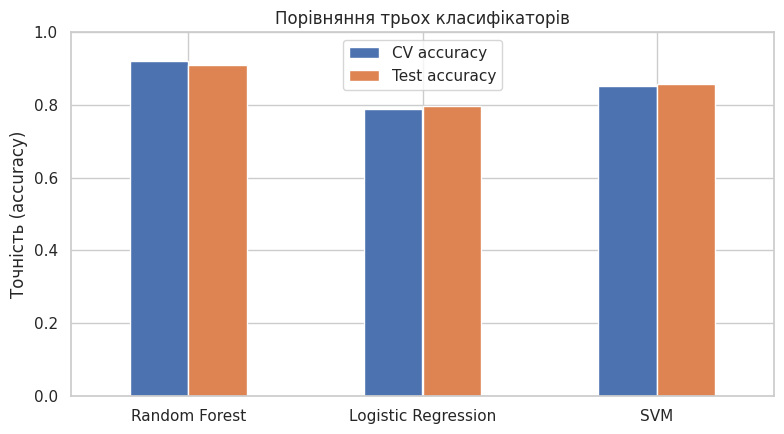

Найкраща за CV: Random Forest
Класифікаційний звіт лише для вибраної моделі на тесті:
              precision    recall  f1-score   support

           0       1.00      0.29      0.44        21
           1       0.82      0.85      0.84        54
           2       0.89      0.95      0.92        78
           3       0.89      0.89      0.89        83
           4       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



In [18]:
if DATA_READY:
    comparison = pd.DataFrame.from_dict(model_results, orient="index",
                                         columns=["CV accuracy", "Test accuracy"])
    display(comparison.sort_values("CV accuracy", ascending=False).round(4))
    comparison.plot(kind="bar", figsize=(8, 4.5), ylim=(0, 1), rot=0)
    plt.title("Порівняння трьох класифікаторів")
    plt.ylabel("Точність (accuracy)")
    plt.tight_layout()
    plt.show()

    # Модель вибираємо за CV, а не тестовою accuracy.
    best_name = comparison["CV accuracy"].idxmax()
    best_model = model_searches[best_name].best_estimator_
    y_pred = best_model.predict(X_test)
    print(f"Найкраща за CV: {best_name}")
    print("Класифікаційний звіт лише для вибраної моделі на тесті:")
    print(classification_report(y_test, y_pred, zero_division=0))

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

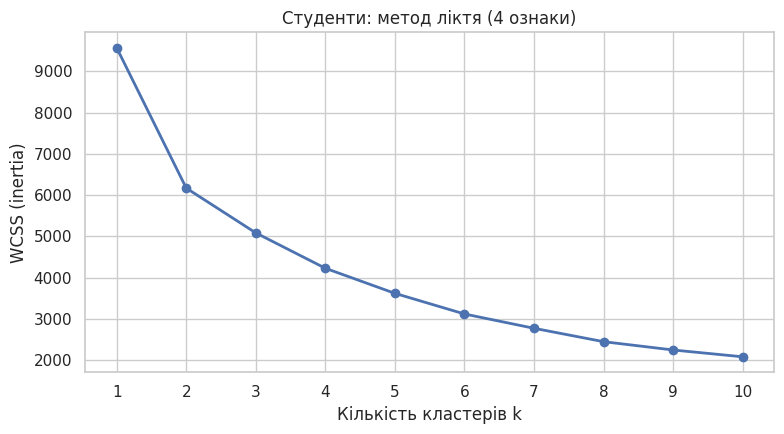

WCSS: {1: np.float64(9568.0), 2: np.float64(6170.46), 3: np.float64(5086.07), 4: np.float64(4229.41), 5: np.float64(3621.89), 6: np.float64(3122.17), 7: np.float64(2775.91), 8: np.float64(2451.74), 9: np.float64(2250.55), 10: np.float64(2085.6)}


In [20]:
if DATA_READY:
    student_features = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
    student_input = df[student_features].apply(pd.to_numeric, errors="coerce")
    student_input = student_input.fillna(student_input.median())
    student_scaler = StandardScaler()
    student_scaled = student_scaler.fit_transform(student_input)
    student_ks = range(1, 11)
    student_wcss = [KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
                    .fit(student_scaled).inertia_ for k in student_ks]
    plt.figure(figsize=(8, 4.5))
    plt.plot(list(student_ks), student_wcss, "o-", linewidth=2)
    plt.xticks(list(student_ks))
    plt.title("Студенти: метод ліктя (4 ознаки)")
    plt.xlabel("Кількість кластерів k")
    plt.ylabel("WCSS (inertia)")
    plt.tight_layout()
    plt.show()
    print("WCSS:", dict(zip(student_ks, np.round(student_wcss, 2))))

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

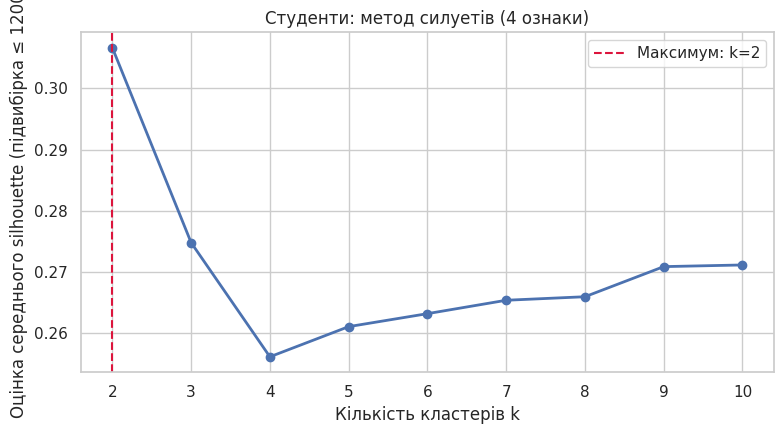

Найкраще k за силуетом: 2; оцінка silhouette=0.3066


In [21]:
if DATA_READY:
    student_silhouette = {}
    for k in range(2, 11):
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE,
                        n_init=10).fit_predict(student_scaled)
        # Для великого набору оцінка на відтворюваній підвибірці прискорює обчислення.
        student_silhouette[k] = silhouette_score(
            student_scaled, labels, sample_size=min(1200, len(student_scaled)),
            random_state=RANDOM_STATE
        )
    student_best_k = max(student_silhouette, key=student_silhouette.get)
    plt.figure(figsize=(8, 4.5))
    plt.plot(list(student_silhouette), list(student_silhouette.values()), "o-", linewidth=2)
    plt.axvline(student_best_k, color="crimson", linestyle="--",
                label=f"Максимум: k={student_best_k}")
    plt.xticks(range(2, 11))
    plt.title("Студенти: метод силуетів (4 ознаки)")
    plt.xlabel("Кількість кластерів k")
    plt.ylabel("Оцінка середнього silhouette (підвибірка ≤ 1200)")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(f"Найкраще k за силуетом: {student_best_k}; "
          f"оцінка silhouette={student_silhouette[student_best_k]:.4f}")

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

**Використовується інший набір ознак:** усі стовпці, крім `StudentID` і `GradeClass`. Це окремий експеримент, тож результат не потрібно безпосередньо порівнювати з чотирма ознаками попередніх кроків. Для вибору числа компонент використовуємо `KneeLocator`; якщо бібліотека недоступна, пропонуємо явно позначений резервний геометричний критерій.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
# За потреби виконайте у Colab / Jupyter окремо: %pip install kneed yellowbrick
# Не встановлюємо бібліотеки автоматично: без інтернету ноутбук теж працює.
try:
    import kneed
    print("kneed доступний")
except ImportError:
    print("kneed відсутній — буде використано резервний критерій")
try:
    import yellowbrick
    print("yellowbrick доступний")
except ImportError:
    print("yellowbrick відсутній — графік ліктя побудуємо Matplotlib")

kneed відсутній — буде використано резервний критерій
yellowbrick доступний


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [23]:
try:
    from kneed import KneeLocator
except ImportError:
    KneeLocator = None
import numpy as np
from sklearn.decomposition import PCA
print("PCA готова. KneeLocator:", "доступний" if KneeLocator else "резервний режим")

PCA готова. KneeLocator: резервний режим


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [24]:
if DATA_READY:
    pca_features = df.drop(columns=["StudentID", "GradeClass"])
    pca_features = pca_features.apply(pd.to_numeric, errors="coerce")
    pca_features = pca_features.fillna(pca_features.median())
    print(f"Ознак для PCA: {pca_features.shape[1]}")
    print("Список:", pca_features.columns.tolist())

Ознак для PCA: 13
Список: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [25]:
if DATA_READY:
    pca_scaler = StandardScaler()
    pca_scaled = pca_scaler.fit_transform(pca_features)
    pca_full = PCA().fit(pca_scaled)
    explained_ratio = pca_full.explained_variance_ratio_
    components_axis = np.arange(1, len(explained_ratio) + 1)
    cumulative_variance = np.cumsum(explained_ratio)
    display(pd.DataFrame({"Компонента": components_axis,
                          "Пояснена дисперсія": explained_ratio,
                          "Накопичена частка": cumulative_variance}).round(4))

,Компонента,Пояснена дисперсія,Накопичена частка
0,1,0.1525,0.1525
1,2,0.0861,0.2386
2,3,0.0827,0.3213
3,4,0.0807,0.4020
4,5,0.0786,0.4806
5,6,0.0779,0.5586
6,7,0.0763,0.6349
7,8,0.0760,0.7109
8,9,0.0744,0.7853
9,10,0.0738,0.8591


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

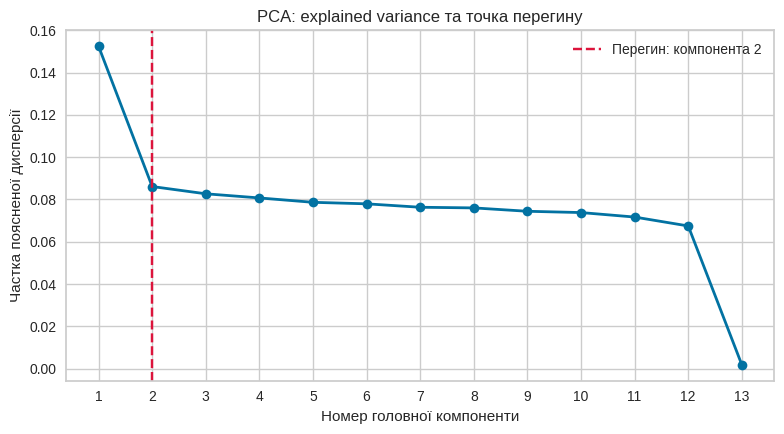

Компонент обрано: 2; спосіб: геометричний резервний критерій


In [26]:
if DATA_READY:
    # Згідно з методичкою x = 1, 2, ..., n (НЕ індекс, що починається з 0).
    knee_component = None
    knee_method = None
    if KneeLocator is not None:
        locator = KneeLocator(components_axis, explained_ratio,
                              curve="convex", direction="decreasing")
        if locator.knee is not None:
            knee_component = int(locator.knee)
            knee_method = "KneeLocator"

    if knee_component is None:
        # Геометрична резервна оцінка вигину: найбільша відстань від хорди
        # між першою й останньою точками нормалізованого спадного графіка.
        x_norm = (components_axis - 1) / max(len(components_axis) - 1, 1)
        spread = max(float(np.ptp(explained_ratio)), 1e-12)
        y_norm = (explained_ratio - explained_ratio[-1]) / spread
        distances = np.abs(y_norm + x_norm - 1) / np.sqrt(2)
        knee_component = int(components_axis[np.argmax(distances)])
        knee_method = "геометричний резервний критерій"

    # Мінімум 2 компоненти для графіків зручний, але при 1 залишаємо 1,
    # якщо саме такий результат визначено алгоритмом.
    n_components = knee_component
    plt.figure(figsize=(8, 4.5))
    plt.plot(components_axis, explained_ratio, "o-", linewidth=2)
    plt.axvline(n_components, color="crimson", linestyle="--",
                label=f"Перегин: компонента {n_components}")
    plt.xlabel("Номер головної компоненти")
    plt.ylabel("Частка поясненої дисперсії")
    plt.title("PCA: explained variance та точка перегину")
    plt.xticks(components_axis)
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(f"Компонент обрано: {n_components}; спосіб: {knee_method}")

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

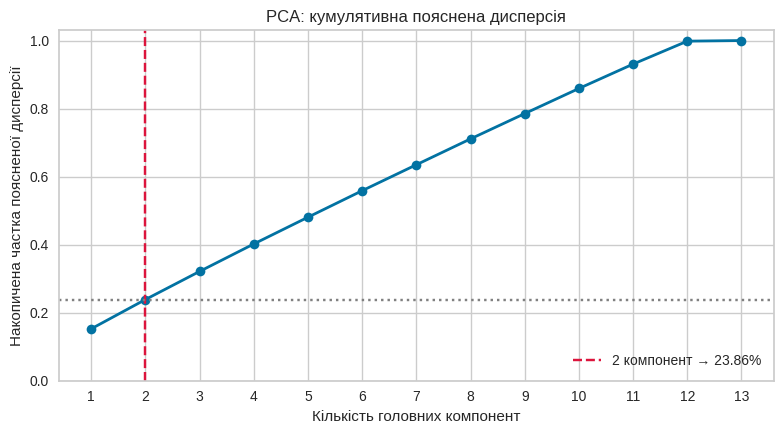

Обрано 2 компонент із 13; вони пояснюють 23.86% дисперсії.
Розмір після PCA: (2392, 2)


In [27]:
if DATA_READY:
    explained_selected = float(cumulative_variance[n_components - 1])
    plt.figure(figsize=(8, 4.5))
    plt.plot(components_axis, cumulative_variance, "o-", linewidth=2)
    plt.axvline(n_components, color="crimson", linestyle="--",
                label=f"{n_components} компонент → {explained_selected:.2%}")
    plt.axhline(explained_selected, color="gray", linestyle=":")
    plt.ylim(0, 1.03)
    plt.xticks(components_axis)
    plt.xlabel("Кількість головних компонент")
    plt.ylabel("Накопичена частка поясненої дисперсії")
    plt.title("PCA: кумулятивна пояснена дисперсія")
    plt.legend()
    plt.tight_layout()
    plt.show()
    pca_selected = PCA(n_components=n_components).fit(pca_scaled)
    pca_transformed = pca_selected.transform(pca_scaled)
    print(f"Обрано {n_components} компонент із {len(components_axis)}; "
          f"вони пояснюють {explained_selected:.2%} дисперсії.")
    print("Розмір після PCA:", pca_transformed.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [28]:
try:
    from yellowbrick.cluster import KElbowVisualizer
except ImportError:
    KElbowVisualizer = None
print("KElbowVisualizer:", "доступний" if KElbowVisualizer else "резервний графік")

KElbowVisualizer: доступний


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

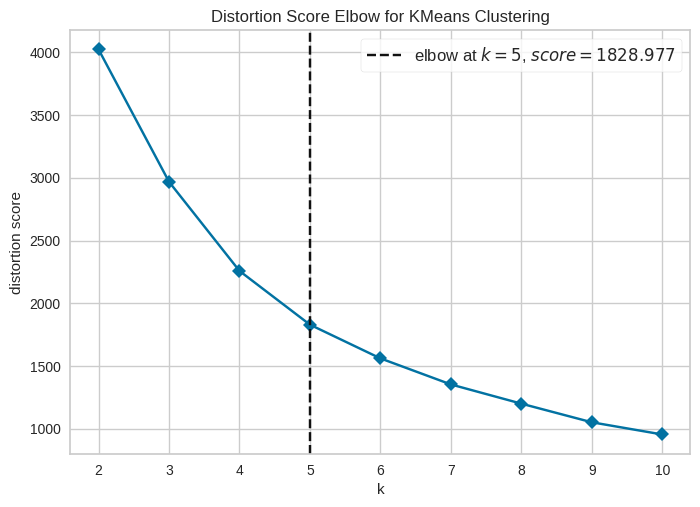

KElbowVisualizer: k у точці ліктя = 5


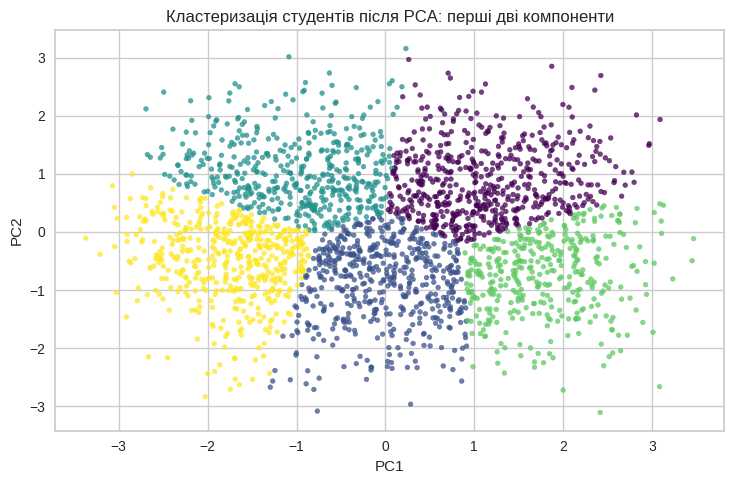

In [29]:
if DATA_READY:
    pca_k_values = list(range(2, 11))
    if KElbowVisualizer is not None:
        visualizer = KElbowVisualizer(
            KMeans(random_state=RANDOM_STATE, n_init=10),
            k=(2, 11), metric="distortion", timings=False
        )
        visualizer.fit(pca_transformed)
        visualizer.show()
        pca_elbow_k = visualizer.elbow_value_
        print("KElbowVisualizer: k у точці ліктя =", pca_elbow_k)
    else:
        pca_inertia = [KMeans(n_clusters=k, random_state=RANDOM_STATE,
                              n_init=10).fit(pca_transformed).inertia_
                       for k in pca_k_values]
        # Резервне визначення ліктя в точці максимальної відстані до хорди.
        xa = np.linspace(0, 1, len(pca_k_values))
        ya = (np.asarray(pca_inertia) - pca_inertia[-1]) / max(
            pca_inertia[0] - pca_inertia[-1], 1e-12)
        pca_elbow_k = pca_k_values[int(np.argmax(np.abs(ya + xa - 1)))]
        plt.figure(figsize=(8, 4.5))
        plt.plot(pca_k_values, pca_inertia, "o-", linewidth=2)
        plt.axvline(pca_elbow_k, color="crimson", linestyle="--",
                    label=f"Оцінка ліктя: k={pca_elbow_k}")
        plt.xticks(pca_k_values)
        plt.xlabel("Кількість кластерів k")
        plt.ylabel("WCSS (inertia)")
        plt.title("Метод ліктя після PCA (резервний алгоритм)")
        plt.legend()
        plt.tight_layout()
        plt.show()
        print("Оцінка ліктя за геометричним критерієм: k =", pca_elbow_k)

    if pca_transformed.shape[1] >= 2:
        clusters_for_plot = KMeans(n_clusters=pca_elbow_k or 2,
                                   random_state=RANDOM_STATE, n_init=10)
        pca_cluster_labels = clusters_for_plot.fit_predict(pca_transformed)
        plt.figure(figsize=(7.5, 5))
        plt.scatter(pca_transformed[:, 0], pca_transformed[:, 1],
                    c=pca_cluster_labels, cmap="viridis", s=12, alpha=0.75)
        plt.xlabel("PC1")
        plt.ylabel("PC2")
        plt.title("Кластеризація студентів після PCA: перші дві компоненти")
        plt.tight_layout()
        plt.show()

## Висновки

1. **Iris.** При стандартизації перших трьох ознак метод ліктя показав зменшення внутрішньокластерної суми квадратів (WCSS) із найбільшим спадом за малих `k`. Найвищий коефіцієнт силуета отримано для `k=2`, тому фінальна модель K-Means має два кластери. Відображення у двох координатах не означає, що кластеризацію здійснено лише за двома ознаками.
2. **Класифікація студентів.** Random Forest, Logistic Regression і SVM навчаються прогнозувати відому цільову змінну **`GradeClass`**. Обираємо модель за найбільшою **CV accuracy** на тренувальному наборі, тест використовуємо лише для оцінювання. Залишена згідно з методичкою ознака `GPA` може бути тісно пов'язана з `GradeClass`, тому результати прогнозу слід інтерпретувати обережно.
3. **Кластеризація студентів.** Для K-Means цільові мітки `GradeClass` **не** використовуються. Кількість кластерів порівнюємо за WCSS (метод ліктя) і коефіцієнтом силуета. Для силуета студентів використовується відтворювана підвибірка до 1200 записів, тому її показник є оцінкою.
4. **PCA.** Для всіх ознак, окрім `StudentID` та `GradeClass`, проведено масштабування та PCA, вибрано число компонент за перегином кривої, а кумулятивну частку поясненої дисперсії обчислено без жодної заздалегідь заданої константи. Після цього метод ліктя застосовано до **перетворених PCA-даних**. Це інший експеримент порівняно з кластеризацією лише за 4 ознаками.

Числовий підсумок, обчислений під час виконання ноутбука, наведено нижче. Якщо оригінальний CSV недоступний, підсумок не приписує студентському набору неотриманих результатів.

In [30]:
print("===== ПІДСУМОК ЛАБОРАТОРНОЇ №8 =====")
print(f"Iris: вибір силуета — k={iris_best_sil_k}, "
      f"силует = {iris_silhouette[iris_best_sil_k]:.4f}; фінальна модель — k=2")
if DATA_READY:
    print(f"Студенти: {len(df)} записів; найкраща CV-модель — {best_name}, "
          f"CV accuracy={model_results[best_name][0]:.4f}, "
          f"Test accuracy={model_results[best_name][1]:.4f}")
    print(f"Кластеризація студентів (4 ознаки): k={student_best_k}, "
          f"silhouette≈{student_silhouette[student_best_k]:.4f}")
    print(f"PCA: {n_components} головних компонент; "
          f"пояснена дисперсія={explained_selected:.2%}; "
          f"оцінка ліктя після PCA: k={pca_elbow_k}")
else:
    print("Реальний CSV студентів не був доступний в цьому середовищі. "
          "Для результатів завдання 2 додайте його та перезапустіть ноутбук.")

===== ПІДСУМОК ЛАБОРАТОРНОЇ №8 =====
Iris: вибір силуета — k=2, силует = 0.5525; фінальна модель — k=2
Студенти: 2392 записів; найкраща CV-модель — Random Forest, CV accuracy=0.9200, Test accuracy=0.9102
Кластеризація студентів (4 ознаки): k=2, silhouette≈0.3066
PCA: 2 головних компонент; пояснена дисперсія=23.86%; оцінка ліктя після PCA: k=5
